In [1]:
import pandas as pd
import numpy as np
import re
!pip install pymorphy2
import pymorphy2


RANDOM_STATE = 42

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.5/55.5 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.2/8.2 MB 37.9 MB/s eta 0:00:00
  Created wheel for docopt: filename=docopt-0.6.2-py2.py3-none-any.whl size=13706 sha256=6eda331ad3fecb178f5ba96f95a5dcbecdd732761a195e92d834f54e0de398f0
  Stored in directory: /root/.cache/pip/wheels/fc/ab/d4/5da2067ac95b36618c629a5f93f809425700506f72c9732fac
Successfully built docopt


### Загрузка датасета

In [2]:
!unzip -o data.zip -d data

Archive:  data.zip
  inflating: data/3.csv              
  inflating: data/1.csv              
  inflating: data/2.csv              


#### 2. датасет 2


In [3]:
df = pd.read_csv('data/2.csv')
print(df.shape)
df.head(10)

(13972, 2)


,comment,toxic
0,сегодня проезжать рабочий дом снитенко гомолыс...,0
1,очередной лохотрон придумывать очередной налог...,0
2,ретро дежавю сложно понять чужое сердце лиш ощ...,0
3,статус агрогородок получить,0
4,август поздно вечером наслать такой потеряшка ...,0
5,вчера надыбал новый стикер,0
6,стоянка никто проверять безопасность ребёнок в...,0
7,красота показать почемунуть,0
8,ходунок цена,0
9,любовьс первый взгляд,0


In [4]:
LABELS_COUNT = 8

#### mini eda, detailed: https://github.com/hse-toxic/toxiccc/blob/mssilenin/eda/ok/eda/ok/nlp_ok_eda.ipynb

In [9]:
labels = {0: 'NORMAL', 1: 'INSULT_THREAT', 2: 'THREAT', 3: 'OBSCENITY', 4: 'INSULT', 5: 'INSULT_OBSCENITY', 6: 'INSULT_OBSCENITY_THREAT', 7: 'OBSCENITY_THREAT'}
labels

{0: 'NORMAL',
 1: 'INSULT_THREAT',
 2: 'THREAT',
 3: 'OBSCENITY',
 4: 'INSULT',
 5: 'INSULT_OBSCENITY',
 6: 'INSULT_OBSCENITY_THREAT',
 7: 'OBSCENITY_THREAT'}

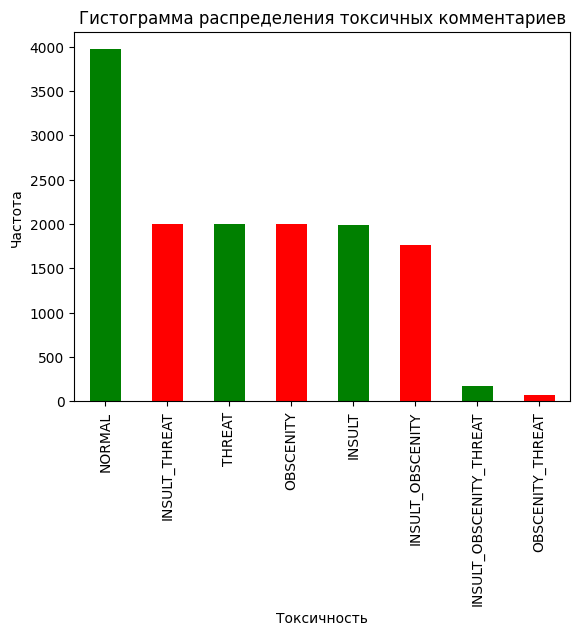

In [10]:
import matplotlib.pyplot as plt

df['toxic'].apply(lambda label: labels[label]).value_counts().plot(kind='bar', color=['green', 'red'])
plt.xlabel('Токсичность')
plt.ylabel('Частота')
plt.title('Гистограмма распределения токсичных комментариев')
plt.show()

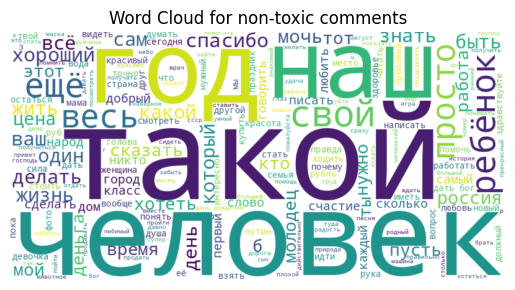

In [11]:
from wordcloud import WordCloud
from functools import reduce


wordcloud_toxic = WordCloud(width=800, height=400, background_color='white').generate(' '.join(df[df['toxic'] == 0.0]['comment'].values))
plt.imshow(wordcloud_toxic, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud for non-toxic comments')
plt.show()

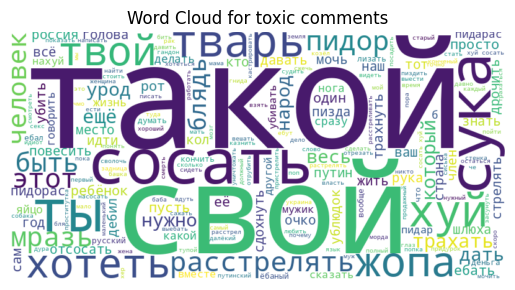

In [12]:
wordcloud_toxic = WordCloud(width=800, height=400, background_color='white').generate(' '.join(df[df['toxic'] != 0.0]['comment'].values))
plt.imshow(wordcloud_toxic, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud for toxic comments')
plt.show()

#### train test split

In [13]:
from sklearn.model_selection import train_test_split
df_train, df_test = train_test_split(df, test_size=0.33, random_state=RANDOM_STATE)
y_train = df_train['toxic']
y_true = df_test['toxic']

## Baseline

In [19]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

metrics = dict()

def get_metrics(y_true, y_pred, title=None):
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(3, 3))

    ax = sns.heatmap(cm, annot=True, fmt='d', cbar=False, cmap=sns.color_palette("pastel", 5))
    ax.set_xlabel("Predicted", labelpad=20)
    ax.set_ylabel("Actual", labelpad=20)
    if title:
        ax.set_title(title)
    plt.show()

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')

    print(f'accuracy:\t{accuracy}')
    print(f'precision:\t{precision}')
    print(f'recall:\t\t{recall}')
    print(f'f1:\t\t{f1}')

    if title:
        metrics[title] = dict()
        metrics[title]['accuracy'] = accuracy
        metrics[title]['precision'] = precision
        metrics[title]['recall'] = recall
        metrics[title]['f1'] = f1

### 1. Модель с константным предсказанием

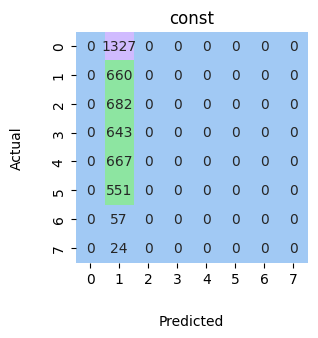

accuracy:	0.14313597918022122
precision:	0.02048790853588072
recall:		0.14313597918022122
f1:		0.03584509438776171


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [20]:
y_pred = np.full(y_true.shape, 1)
get_metrics(y_true, y_pred, 'const')

### 2. Модель со случайным предсказанием

In [21]:
class BaseLineModel():
    def __init__(self, predict_function):
        self.predict_function = predict_function

    def predict(self, X):
        return np.array(list(map(self.predict_function, X)))

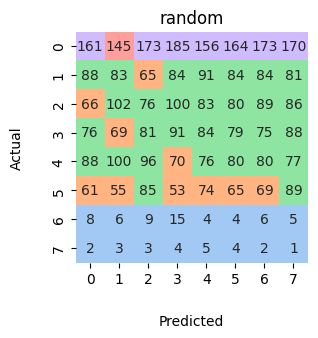

accuracy:	0.12123183691173281
precision:	0.1787359727278752
recall:		0.12123183691173281
f1:		0.13885089652660276


In [22]:
def random_prediction(comment):
    return np.random.randint(0, LABELS_COUNT)


random_model = BaseLineModel(random_prediction)
y_pred = random_model.predict(df_test['comment'])
get_metrics(y_true, y_pred, 'random')

### 3. Lexicon-based

In [23]:
nltk.download('punkt')
nltk.download('punkt_tab')

from nltk import word_tokenize
from nltk.probability import FreqDist
from nltk.corpus import stopwords
from nltk.util import ngrams

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


In [25]:
toxic_dict = dict()
for i in range(1, LABELS_COUNT):
    comments = " ".join(df_train[df_train['toxic'] == i]['comment'].tolist())
    comments_tokens = word_tokenize(comments)
    text = nltk.Text(comments_tokens)
    f_dist = FreqDist(text)
    toxic_dict[i] = set(map(lambda x: x[0], f_dist.most_common(20)))
print(toxic_dict)

{1: {'ты', 'расстрелять', 'свой', 'рука', 'кол', 'ребёнок', 'сдохнуть', 'человек', 'тварь', 'пидор', 'ублюдок', 'мразь', 'урод', 'сука', 'нужно', 'этот', 'такой', 'убить', 'народ', 'яйцо'}, 2: {'расстрелять', 'стрелять', 'рука', 'кол', 'расстреливать', 'отрубить', 'человек', 'сразу', 'казнить', 'убивать', 'сжечь', 'расстрел', 'нужно', 'такой', 'оторвать', 'убить', 'народ', 'повесить', 'яйцо', 'растрелять'}, 3: {'ты', 'твой', 'рот', 'хотеть', 'член', 'лизать', 'ебать', 'трахать', 'хуй', 'вдуть', 'дрочить', 'её', 'отсосать', 'такой', 'быть', 'сосать', 'попка', 'жопа', 'дать', 'трахнуть'}, 4: {'идти', 'свой', 'дебил', 'россия', 'человек', 'блядь', 'тварь', 'хуй', 'пидор', 'мразь', 'урод', 'сука', 'один', 'который', 'этот', 'такой', 'быть', 'страна', 'всё', 'пидорас'}, 5: {'твой', 'рот', 'ты', 'хотеть', 'идти', 'свой', 'ебать', 'шлюха', 'трахать', 'блядь', 'хуй', 'пидор', 'очко', 'сука', 'отсосать', 'такой', 'ебал', 'быть', 'сосать', 'жопа'}, 6: {'твой', 'рот', 'ты', 'свой', 'весь', 'ебать

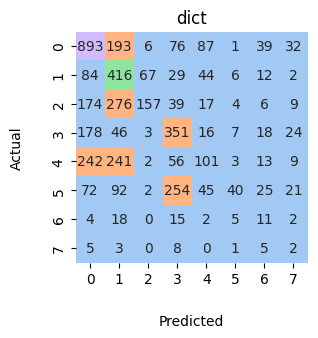

accuracy:	0.42745608327911516
precision:	0.4783258082243797
recall:		0.42745608327911516
f1:		0.39779670115114346


In [26]:
def dict_prediction(comment):
    for word in comment.split(' '):
        for label in toxic_dict:
            if word in toxic_dict[label]:
                return label
    return 0


dict_model = BaseLineModel(dict_prediction)
y_pred = dict_model.predict(df_test['comment'])
get_metrics(y_true, y_pred, 'dict')

### 4. Rule-based

In [27]:
!pip install fkscore
import fkscore

In [28]:
df_test_copy = df_test.copy()
df_test_copy['fkscore'] = df_test_copy['comment'].apply(lambda comment: fkscore.fkscore(comment).score['readability'])
print(df_test_copy[df_test_copy['toxic'] == 0]['fkscore'].describe())
print()
print(df_test_copy[df_test_copy['toxic'] != 0]['fkscore'].describe())

count    1327.000000
mean      114.648124
std         9.899234
min        13.630000
25%       114.115000
50%       118.175000
75%       119.190000
max       121.220000
Name: fkscore, dtype: float64

count    3284.000000
mean      115.011625
std         7.501578
min        37.990000
25%       114.115000
50%       117.160000
75%       119.190000
max       121.220000
Name: fkscore, dtype: float64


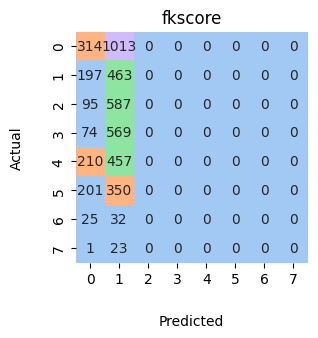

accuracy:	0.16851008458035133
precision:	0.099868060014459
recall:		0.16851008458035133
f1:		0.10585686880893179


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [32]:
def fkscore_prediction(comment):
    score = fkscore.fkscore(comment).score
    return score['readability'] > 114


fkscore_model = BaseLineModel(fkscore_prediction)
y_pred = fkscore_model.predict(df_test['comment'])
get_metrics(y_true, y_pred, 'fkscore')

### 5. BoW

#### 5.1 Logistic Regression

In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import CountVectorizer


vectorizer = CountVectorizer()
vectorizer.fit(df_train['comment'])
X_train = vectorizer.transform(df_train['comment'])
X_test = vectorizer.transform(df_test['comment'])
lr = LogisticRegression()
lr.fit(X_train, y_train)

LogisticRegression()

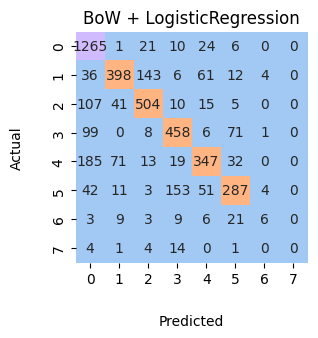

accuracy:	0.7080893515506398
precision:	0.6991030452331664
recall:		0.7080893515506398
f1:		0.6944073493482453


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [34]:
y_pred = lr.predict(X_test)
get_metrics(y_true, y_pred, 'BoW + LogisticRegression')

#### 5.2 SVC

In [35]:
from sklearn import svm


clf = svm.SVC()
clf.fit(X_train, y_train)

SVC()

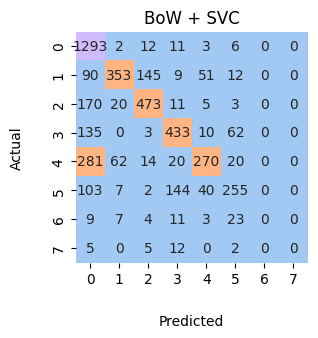

accuracy:	0.6673172847538494
precision:	0.6712961636920534
recall:		0.6673172847538494
f1:		0.6464713994952844


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [36]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'BoW + SVC')

### 6. TF-IDF

#### 6.1 LogisticRegression

In [37]:
from sklearn.feature_extraction.text import TfidfVectorizer


vectorizer = TfidfVectorizer()
vectorizer.fit(df_train['comment'])
X_train = vectorizer.transform(df_train['comment'])
X_test = vectorizer.transform(df_test['comment'])
lr = LogisticRegression()
lr.fit(X_train, y_train)

LogisticRegression()

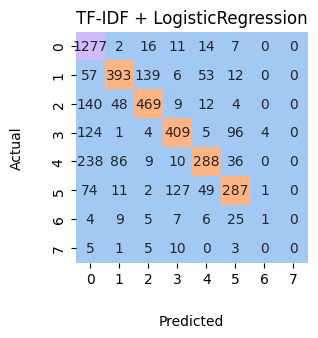

accuracy:	0.677510301453047
precision:	0.6699148565782527
recall:		0.677510301453047
f1:		0.6598981898560602


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [38]:
y_pred = lr.predict(X_test)
get_metrics(y_true, y_pred, 'TF-IDF + LogisticRegression')

#### 6.2 SVC

In [39]:
from sklearn import svm


clf = svm.SVC()
clf.fit(X_train, y_train)

SVC()

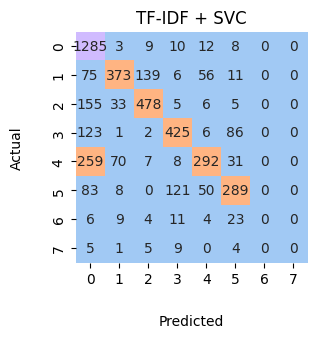

accuracy:	0.681414009976144
precision:	0.677058393861797
recall:		0.681414009976144
f1:		0.6633133000168149


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [40]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'TF-IDF + SVC')

#### 6.3 GradientBoosting

In [41]:
from sklearn.ensemble import GradientBoostingClassifier


clf = GradientBoostingClassifier(n_estimators=100, learning_rate=1.0, max_depth=1, random_state=RANDOM_STATE)
clf.fit(X_train, y_train)

GradientBoostingClassifier(learning_rate=1.0, max_depth=1, random_state=42)

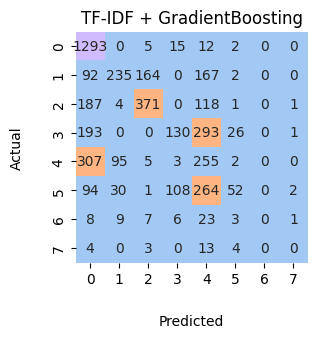

accuracy:	0.506614617219692
precision:	0.5286731035830404
recall:		0.506614617219692
f1:		0.46621021276842406


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [42]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'TF-IDF + GradientBoosting')

### 7. N-grams + Naive Byas

In [43]:
from sklearn.naive_bayes import MultinomialNB


vectorizer = CountVectorizer(ngram_range=(1, 2))
vectorizer.fit(df_train['comment'])
X_train = vectorizer.transform(df_train['comment'])
X_test = vectorizer.transform(df_test['comment'])
clf = MultinomialNB()
clf.fit(X_train, y_train)

MultinomialNB()

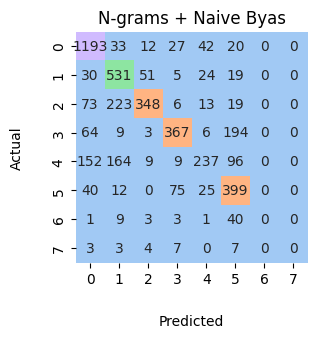

accuracy:	0.6668835393623943
precision:	0.6787187094846973
recall:		0.6668835393623943
f1:		0.6512964102342307


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [44]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'N-grams + Naive Byas')

### 8. Word2Vec

#### 8.1 LogisticRegression

In [45]:
from gensim.models import Word2Vec

VECTOR_SIZE = 100
sentences = [sentence.split() for sentence in df_train['comment']]
w2v_model = Word2Vec(sentences, vector_size=VECTOR_SIZE, window=5, min_count=5, workers=4)

In [49]:
def vectorize(comment):
    words = comment.split()
    words_vecs = [w2v_model.wv[word] for word in words if word in w2v_model.wv]
    if len(words_vecs) == 0:
        return np.zeros(VECTOR_SIZE)
    words_vecs = np.array(words_vecs)
    return words_vecs.mean(axis=0)


X_train = np.array([vectorize(comment) for comment in df_train['comment']])
X_test = np.array([vectorize(comment) for comment in df_test['comment']])
clf = LogisticRegression(max_iter=150)
clf.fit(X_train, y_train)

LogisticRegression(max_iter=150)

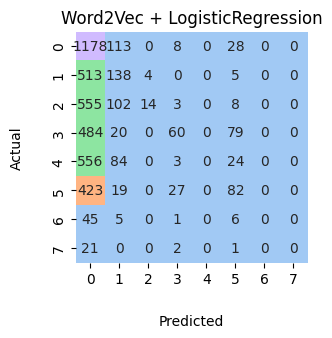

accuracy:	0.3192366081110388
precision:	0.36841682064354425
recall:		0.3192366081110388
f1:		0.22083375869657487


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [50]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'Word2Vec + LogisticRegression')

#### 8.2 KNN

In [51]:
from sklearn.neighbors import KNeighborsClassifier


clf = KNeighborsClassifier(n_neighbors=3)
clf.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

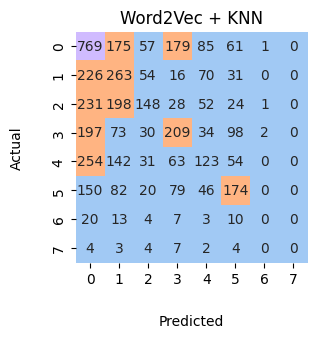

accuracy:	0.3656473649967469
precision:	0.36017054816376004
recall:		0.3656473649967469
f1:		0.3501101903446166


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [52]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'Word2Vec + KNN')

#### 8.3 SVC

In [53]:
clf = svm.SVC()
clf.fit(X_train, y_train)

SVC()

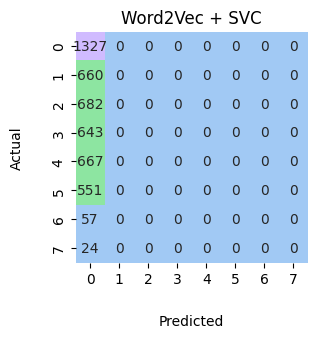

accuracy:	0.2877900672305357
precision:	0.08282312279655624
recall:		0.2877900672305357
f1:		0.12862829882617743


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [54]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'Word2Vec + SVC')

#### 8.4 GradientBoosting

In [55]:
clf = GradientBoostingClassifier(n_estimators=100, learning_rate=1.0, max_depth=1, random_state=RANDOM_STATE)
clf.fit(X_train, y_train)

GradientBoostingClassifier(learning_rate=1.0, max_depth=1, random_state=42)

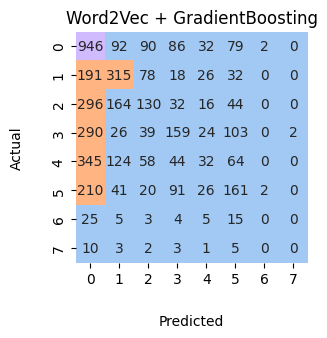

accuracy:	0.37800910865322057
precision:	0.3396003759614055
recall:		0.37800910865322057
f1:		0.3362780817661012


In [56]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'Word2Vec + GradientBoosting')

### 9. GloVe

#### 9.1 LogisticRegression

In [57]:
!pip install navec
!wget https://storage.yandexcloud.net/natasha-navec/packs/navec_hudlit_v1_12B_500K_300d_100q.tar

--2024-12-21 18:09:50--  https://storage.yandexcloud.net/natasha-navec/packs/navec_hudlit_v1_12B_500K_300d_100q.tar
Resolving storage.yandexcloud.net (storage.yandexcloud.net)... 213.180.193.243, 2a02:6b8::1d9
Connecting to storage.yandexcloud.net (storage.yandexcloud.net)|213.180.193.243|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 53012480 (51M) [application/x-tar]
Saving to: ‘navec_hudlit_v1_12B_500K_300d_100q.tar’

navec_hudlit_v1_12B 100%[===================>]  50.56M  16.4MB/s    in 3.7s    

2024-12-21 18:09:54 (13.6 MB/s) - ‘navec_hudlit_v1_12B_500K_300d_100q.tar’ saved [53012480/53012480]



In [58]:
from navec import Navec

path = 'navec_hudlit_v1_12B_500K_300d_100q.tar'
navec = Navec.load(path)

In [59]:
def vectorize(comment):
    words = comment.split()
    words_vecs = [navec[word] for word in words if word in navec]
    if len(words_vecs) == 0:
        return np.zeros(300)
    words_vecs = np.array(words_vecs)
    return words_vecs.mean(axis=0)


X_train = np.array([vectorize(comment) for comment in df_train['comment']])
X_test = np.array([vectorize(comment) for comment in df_test['comment']])
clf = LogisticRegression()
clf.fit(X_train, y_train)

LogisticRegression()

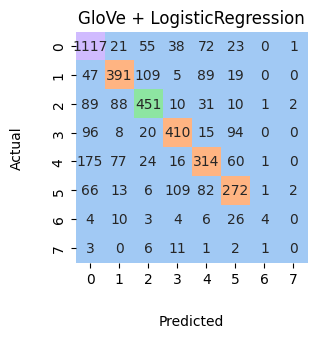

accuracy:	0.6417263066579918
precision:	0.6320047970132938
recall:		0.6417263066579918
f1:		0.632471398993478


In [60]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'GloVe + LogisticRegression')

#### 9.2 KNN

In [61]:
from sklearn.neighbors import KNeighborsClassifier


clf = KNeighborsClassifier(n_neighbors=3)
clf.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

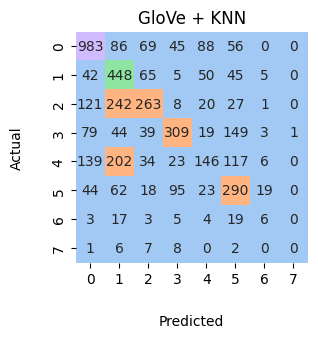

accuracy:	0.5302537410540012
precision:	0.534266900908513
recall:		0.5302537410540012
f1:		0.5188558243658072


In [62]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'GloVe + KNN')

#### 9.3 SVC

In [63]:
clf = svm.SVC()
clf.fit(X_train, y_train)

SVC()

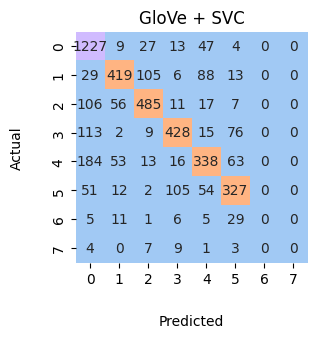

accuracy:	0.6991975710258078
precision:	0.6845398111833555
recall:		0.6991975710258078
f1:		0.6865096175653815


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [64]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'GloVe + SVC')

#### 9.4 GradientBoosting

In [65]:
clf = GradientBoostingClassifier(n_estimators=100, learning_rate=1.0, max_depth=1, random_state=RANDOM_STATE)
clf.fit(X_train, y_train)

GradientBoostingClassifier(learning_rate=1.0, max_depth=1, random_state=42)

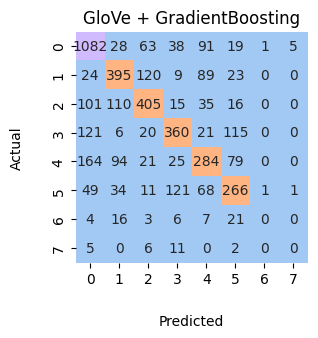

accuracy:	0.6055085664714812
precision:	0.5895898368357869
recall:		0.6055085664714812
f1:		0.5957604426393303


In [66]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'GloVe + GradientBoosting')

### Вывод

In [67]:
metrics_df = pd.DataFrame(metrics).T
cols = metrics_df.columns.tolist()
cols = cols[-1:] + cols[:-1]
metrics_df = metrics_df[cols].sort_values(by=['f1'], ascending=False)
metrics_df

,f1,accuracy,precision,recall
BoW + LogisticRegression,0.694407,0.708089,0.699103,0.708089
GloVe + SVC,0.686510,0.699198,0.684540,0.699198
TF-IDF + SVC,0.663313,0.681414,0.677058,0.681414
TF-IDF + LogisticRegression,0.659898,0.677510,0.669915,0.677510
N-grams + Naive Byas,0.651296,0.666884,0.678719,0.666884
BoW + SVC,0.646471,0.667317,0.671296,0.667317
GloVe + LogisticRegression,0.632471,0.641726,0.632005,0.641726
GloVe + GradientBoosting,0.595760,0.605509,0.589590,0.605509
GloVe + KNN,0.518856,0.530254,0.534267,0.530254
TF-IDF + GradientBoosting,0.466210,0.506615,0.528673,0.506615


Из baseline моделей наилучшие результаты показали BoW + LogisticRegression, GloVe + SVC и TF-IDF + SVC. Стоит отметить, что BoW + LogisticRegression один из самых быстрых методов и при этом находится среди лучших результатов.

